# Phase 2 — Transfer Learning with MobileNetV2

**Purpose:**
Train a MobileNetV2 pretrained backbone with progressive unfreezing using a balanced per-batch generator. Evaluate interpretability using Grad-CAM. Validate decision threshold strictly on the validation set.

In [1]:
print("Check_Python")
%load_ext autotime

Check_Python
time: 0 ns (started: 2026-10-02 21:27:48 +05:30)


In [2]:
import tensorflow as tf
import os
from pathlib import Path
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import load_model

time: 24.1 s (started: 2026-10-02 21:27:48 +05:30)


In [3]:
print(tf.__version__)
print(tf.config.list_physical_devices())

2.20.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
time: 0 ns (started: 2026-10-02 21:28:13 +05:30)


In [4]:
PROJECT_ROOT = Path().resolve().parent
DATA_DIR = PROJECT_ROOT / "data"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "val"
TEST_DIR  = DATA_DIR / "test"

MODELS_DIR = PROJECT_ROOT / "models" / "phase2"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDS_DIR = RESULTS_DIR / "predictions"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PREDS_DIR.mkdir(parents=True, exist_ok=True)

print(TRAIN_DIR.exists(), VAL_DIR.exists(), TEST_DIR.exists(), MODELS_DIR.exists())

True True True True
time: 0 ns (started: 2026-10-02 21:28:13 +05:30)


In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
COLOR_MODE = "rgb"
SEED = 42

time: 16 ms (started: 2026-10-02 21:28:13 +05:30)


In [6]:
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

time: 31 ms (started: 2026-10-02 21:28:13 +05:30)


## Data Loading
Note: Generators yield raw 0-255 RGB pixels. The MobileNetV2 preprocessing (rescaling) is baked directly into the model via a `Rescaling` layer.

In [7]:
def make_balanced_gen(paths, labels, batch_size=32, datagen=None):
    pos_idx = np.where(labels == 1)[0]
    neg_idx = np.where(labels == 0)[0]

    while True:
        batch_paths, batch_labels = [], []

        for _ in range(batch_size // 2):
            p = np.random.choice(pos_idx)
            n = np.random.choice(neg_idx)

            batch_paths += [paths[p], paths[n]]
            batch_labels += [1, 0]

        combined = list(zip(batch_paths, batch_labels))
        random.shuffle(combined)
        batch_paths, batch_labels = zip(*combined)

        images = []
        for path in batch_paths:
            img = tf.keras.utils.load_img(
                path, 
                color_mode="rgb", 
                target_size=IMG_SIZE, 
                interpolation="bilinear"
            )
            img = tf.keras.utils.img_to_array(img)
            
            if datagen is not None:
                img = datagen.random_transform(img)
                
            images.append(img)

        yield np.array(images, dtype="float32"), np.array(batch_labels)

time: 0 ns (started: 2026-10-02 21:28:13 +05:30)


In [8]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.08,
    height_shift_range=0.08,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

time: 0 ns (started: 2026-10-02 21:28:13 +05:30)


In [9]:
VALID_EXTS = {".jpeg", ".jpg", ".png"}

temp_gen = ImageDataGenerator().flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=1, class_mode="binary", shuffle=False, interpolation="bilinear"
)
class_map = temp_gen.class_indices
assert class_map == {"NORMAL": 0, "PNEUMONIA": 1}, f"Unexpected class mapping: {class_map}"

all_paths = []
all_labels = []

for class_name, label in class_map.items():
    class_dir = TRAIN_DIR / class_name
    for img_name in os.listdir(class_dir):
        if img_name.startswith("aug_"):
            continue
        if Path(img_name).suffix.lower() not in VALID_EXTS:
            continue
        all_paths.append(str(class_dir / img_name))
        all_labels.append(label)

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)

print("Total train samples:", len(all_paths))
print("Class distribution:", np.bincount(all_labels))

Found 4769 images belonging to 2 classes.
Total train samples: 4693
Class distribution: [1206 3487]
time: 1.94 s (started: 2026-10-02 21:28:13 +05:30)


In [10]:
val_test_datagen = ImageDataGenerator()

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode=COLOR_MODE, class_mode="binary", shuffle=False, interpolation="bilinear"
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode=COLOR_MODE, class_mode="binary", shuffle=False, interpolation="bilinear"
)

assert val_generator.class_indices == {"NORMAL": 0, "PNEUMONIA": 1}
assert test_generator.class_indices == {"NORMAL": 0, "PNEUMONIA": 1}

Found 539 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
time: 1.58 s (started: 2026-10-02 21:28:15 +05:30)


In [11]:
train_gen = make_balanced_gen(all_paths, all_labels, batch_size=BATCH_SIZE, datagen=train_datagen)
steps_per_epoch = len(all_paths) // BATCH_SIZE

time: 0 ns (started: 2026-10-02 21:28:17 +05:30)


## Model Architecture
Building the model as three named components: `rescale`, `mobilenetv2_base`, and `head` for clean separation during Grad-CAM evaluation.

In [12]:
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3), name="mobilenetv2_base")
base_model.trainable = False

head = tf.keras.Sequential([
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
], name="head")

inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(scale=1/127.5, offset=-1.0, name="rescale")(inputs)
x = base_model(x, training=False)
outputs = head(x)

model = tf.keras.Model(inputs, outputs, name="phase2_model")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 39s 4us/step


Model: "phase2_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_base (Functional)   │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Sequential)               │ (None, 1)              │       328,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,177 (9.87 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

time: 51.5 s (started: 2026-10-02 21:28:17 +05:30)


## Stage 1 — Train Head Only
Base model is frozen. Training the randomly initialized head.

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks_s1 = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    ModelCheckpoint(
        filepath=str(MODELS_DIR / "mobilenetv2_stage1_frozen.h5"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

time: 15 ms (started: 2026-10-02 21:29:08 +05:30)


In [14]:
history_s1 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks_s1
)

Epoch 1/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.8891 - loss: 0.2652
Epoch 1: val_loss improved from None to 0.16370, saving model to X:\AI-Projects\Chest-Xray-Pneumonia-Detection\models\phase2\mobilenetv2_stage1_frozen.h5


146/146 ━━━━━━━━━━━━━━━━━━━━ 1468s 10s/step - accuracy: 0.9247 - loss: 0.1918 - val_accuracy: 0.9295 - val_loss: 0.1637 - learning_rate: 0.0010
Epoch 2/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9502 - loss: 0.1336
Epoch 2: val_loss did not improve from 0.16370
146/146 ━━━━━━━━━━━━━━━━━━━━ 1403s 10s/step - accuracy: 0.9463 - loss: 0.1399 - val_accuracy: 0.8794 - val_loss: 0.3246 - learning_rate: 0.0010
Epoch 3/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.9528 - loss: 0.1348
Epoch 3: val_loss improved from 0.16370 to 0.14791, saving model to X:\AI-Projects\Chest-Xray-Pneumonia-Detection\models\phase2\mobilenetv2_stage1_frozen.h5


146/146 ━━━━━━━━━━━━━━━━━━━━ 1264s 9s/step - accuracy: 0.9525 - loss: 0.1324 - val_accuracy: 0.9388 - val_loss: 0.1479 - learning_rate: 0.0010
Epoch 4/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9635 - loss: 0.1034
Epoch 4: val_loss did not improve from 0.14791
146/146 ━━━━━━━━━━━━━━━━━━━━ 1412s 10s/step - accuracy: 0.9578 - loss: 0.1130 - val_accuracy: 0.9017 - val_loss: 0.2388 - learning_rate: 0.0010
Epoch 5/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9572 - loss: 0.1096
Epoch 5: val_loss did not improve from 0.14791
146/146 ━━━━━━━━━━━━━━━━━━━━ 1343s 9s/step - accuracy: 0.9593 - loss: 0.1056 - val_accuracy: 0.9184 - val_loss: 0.1917 - learning_rate: 0.0010
Epoch 6/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9669 - loss: 0.0924
Epoch 6: val_loss did not improve from 0.14791
146/146 ━━━━━━━━━━━━━━━━━━━━ 1108s 8s/step - accuracy: 0.9681 - loss: 0.0910 - val_accuracy: 0.9221 - val_loss: 0.2027 - learning_rate: 3.0000e-04
Epoch 7/15
146/146 ━━━━━━━━

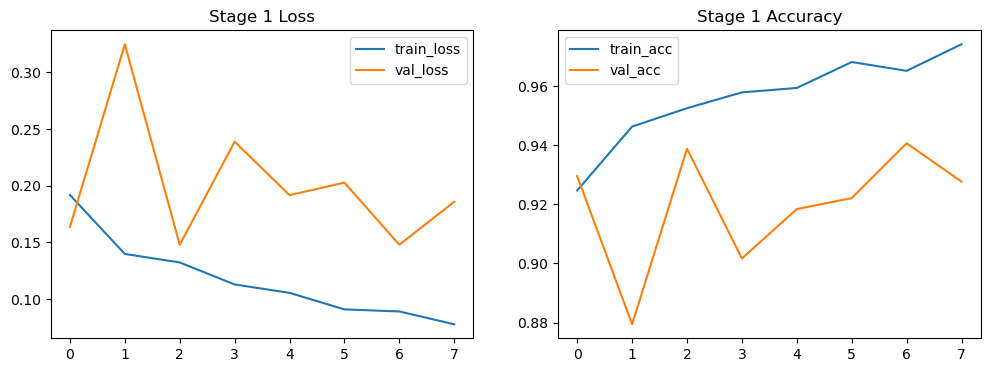

time: 8.58 s (started: 2026-10-03 00:10:11 +05:30)


In [15]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_s1.history['loss'], label='train_loss')
plt.plot(history_s1.history['val_loss'], label='val_loss')
plt.legend()
plt.title('Stage 1 Loss')

plt.subplot(1, 2, 2)
plt.plot(history_s1.history['accuracy'], label='train_acc')
plt.plot(history_s1.history['val_accuracy'], label='val_acc')
plt.legend()
plt.title('Stage 1 Accuracy')
plt.show()

## Stage 2 — Fine-tuning
Unfreezing the top blocks of the base model while keeping BatchNormalization layers frozen.

In [16]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers in base model:", len([l for l in base_model.layers if l.trainable]))

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

Trainable layers in base model: 19
time: 2.31 s (started: 2026-10-03 00:10:20 +05:30)


In [17]:
callbacks_s2 = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    ModelCheckpoint(
        filepath=str(MODELS_DIR / "mobilenetv2_stage2_finetuned.h5"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

time: 32 ms (started: 2026-10-03 00:10:22 +05:30)


In [18]:
history_s2 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks_s2
)

Epoch 1/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9496 - loss: 0.1187
Epoch 1: val_loss improved from None to 0.30449, saving model to X:\AI-Projects\Chest-Xray-Pneumonia-Detection\models\phase2\mobilenetv2_stage2_finetuned.h5


146/146 ━━━━━━━━━━━━━━━━━━━━ 728s 5s/step - accuracy: 0.9572 - loss: 0.1029 - val_accuracy: 0.8942 - val_loss: 0.3045 - learning_rate: 1.0000e-05
Epoch 2/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9647 - loss: 0.0909
Epoch 2: val_loss improved from 0.30449 to 0.18035, saving model to X:\AI-Projects\Chest-Xray-Pneumonia-Detection\models\phase2\mobilenetv2_stage2_finetuned.h5


146/146 ━━━━━━━━━━━━━━━━━━━━ 423s 3s/step - accuracy: 0.9685 - loss: 0.0827 - val_accuracy: 0.9314 - val_loss: 0.1803 - learning_rate: 1.0000e-05
Epoch 3/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9666 - loss: 0.0975
Epoch 3: val_loss improved from 0.18035 to 0.15115, saving model to X:\AI-Projects\Chest-Xray-Pneumonia-Detection\models\phase2\mobilenetv2_stage2_finetuned.h5


146/146 ━━━━━━━━━━━━━━━━━━━━ 331s 2s/step - accuracy: 0.9711 - loss: 0.0896 - val_accuracy: 0.9406 - val_loss: 0.1512 - learning_rate: 1.0000e-05
Epoch 4/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9764 - loss: 0.0751
Epoch 4: val_loss did not improve from 0.15115
146/146 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9765 - loss: 0.0697 - val_accuracy: 0.9239 - val_loss: 0.2471 - learning_rate: 1.0000e-05
Epoch 5/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9756 - loss: 0.0677
Epoch 5: val_loss did not improve from 0.15115
146/146 ━━━━━━━━━━━━━━━━━━━━ 215s 1s/step - accuracy: 0.9747 - loss: 0.0703 - val_accuracy: 0.9332 - val_loss: 0.2126 - learning_rate: 1.0000e-05
Epoch 6/15
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9753 - loss: 0.0753
Epoch 6: val_loss did not improve from 0.15115
146/146 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.9765 - loss: 0.0653 - val_accuracy: 0.9239 - val_loss: 0.2421 - learning_rate: 3.0000e-06
Epoch 7/15
146/146 ━

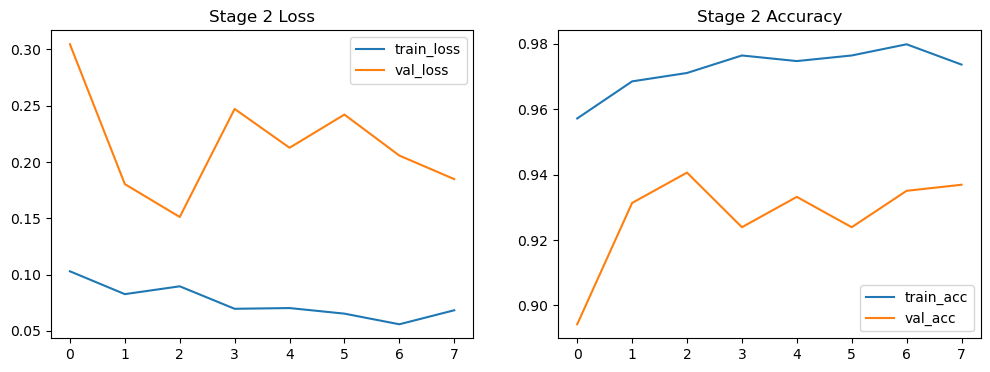

time: 407 ms (started: 2026-10-03 00:51:56 +05:30)


In [19]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_s2.history['loss'], label='train_loss')
plt.plot(history_s2.history['val_loss'], label='val_loss')
plt.legend()
plt.title('Stage 2 Loss')

plt.subplot(1, 2, 2)
plt.plot(history_s2.history['accuracy'], label='train_acc')
plt.plot(history_s2.history['val_accuracy'], label='val_acc')
plt.legend()
plt.title('Stage 2 Accuracy')
plt.show()

## Round-trip Save/Load Check

In [20]:
saved_model = load_model(str(MODELS_DIR / "mobilenetv2_stage2_finetuned.h5"), compile=False)

test_batch_x, test_batch_y = next(iter(val_generator))
preds_in_memory = model.predict(test_batch_x, verbose=0)
preds_from_disk = saved_model.predict(test_batch_x, verbose=0)

if np.allclose(preds_in_memory, preds_from_disk, atol=1e-5):
    print("PASS: Round-trip save/load check passed.")
else:
    print("FAIL: Predictions from disk model do not match in-memory model.")

PASS: Round-trip save/load check passed.
time: 7.98 s (started: 2026-10-03 00:51:57 +05:30)


## Grad-CAM
Visualizing regions driving the 'Pneumonia' prediction. Computed securely under `tf.GradientTape` by splitting the forward pass into base and head.

In [21]:
def make_gradcam_heatmap(img_array, model):
    rescale = model.get_layer("rescale")
    base = model.get_layer("mobilenetv2_base")
    head = model.get_layer("head")
    
    with tf.GradientTape() as tape:
        x = rescale(img_array)
        feats = base(x, training=False)
        tape.watch(feats)
        preds = head(feats)
        
    grads = tape.gradient(preds, feats)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    feats = feats[0]
    heatmap = feats @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

time: 0 ns (started: 2026-10-03 00:52:05 +05:30)


In [22]:
from sklearn.metrics import f1_score

val_generator.reset()
y_val = val_generator.classes
val_preds_raw = saved_model.predict(val_generator).flatten()

best_thresh, best_f1 = 0.5, 0
for t in np.arange(0.2, 0.8, 0.01):
    f1 = f1_score(y_val, (val_preds_raw > t).astype(int))
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t
print(f"Val-tuned threshold: {best_thresh:.2f}")

test_generator.reset()
y_test = test_generator.classes
test_preds_raw = saved_model.predict(test_generator).flatten()
test_preds = (test_preds_raw > best_thresh).astype(int)

tp_idx = np.where((y_test == 1) & (test_preds == 1))[0]
tn_idx = np.where((y_test == 0) & (test_preds == 0))[0]
fp_idx = np.where((y_test == 0) & (test_preds == 1))[0]
fn_idx = np.where((y_test == 1) & (test_preds == 0))[0]

rng = np.random.RandomState(SEED)
def pick_samples(indices, k=2):
    return rng.choice(indices, min(k, len(indices)), replace=False)

sample_indices = {
    "True Positive": pick_samples(tp_idx),
    "True Negative": pick_samples(tn_idx),
    "False Positive": pick_samples(fp_idx),
    "False Negative": pick_samples(fn_idx)
}

17/17 ━━━━━━━━━━━━━━━━━━━━ 15s 757ms/step
Val-tuned threshold: 0.20
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 683ms/step
time: 34.8 s (started: 2026-10-03 00:52:05 +05:30)


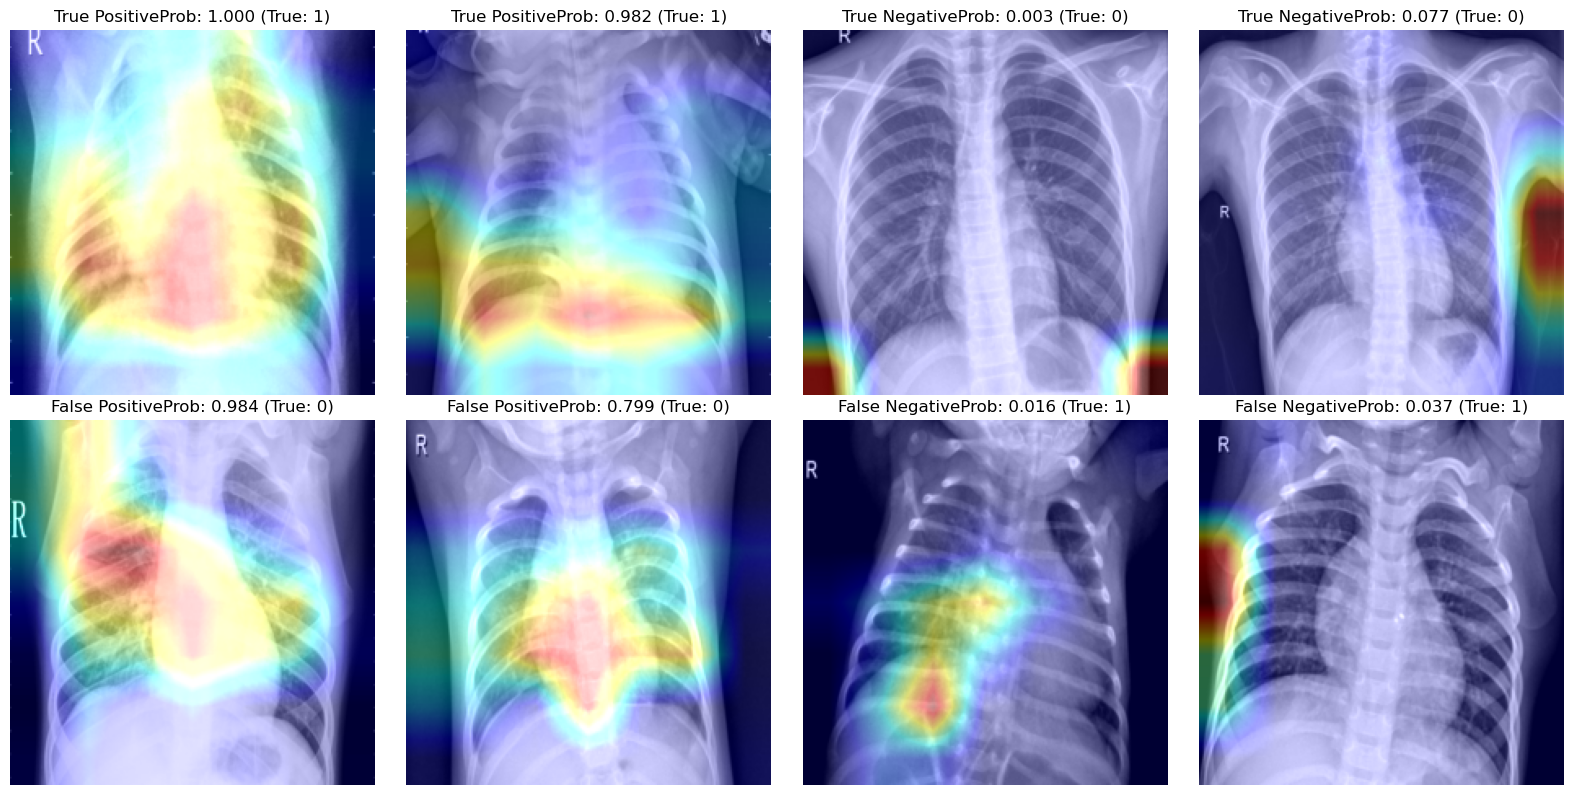

time: 5.94 s (started: 2026-10-03 00:53:27 +05:30)


In [27]:
plt.figure(figsize=(16, 8))
plot_idx = 1

test_filepaths = test_generator.filepaths

for category, indices in sample_indices.items():
    if len(indices) == 0:
        print(f"No samples for {category}")
        continue
        
    for i in indices:
        img_path = test_filepaths[i]
        
        img = tf.keras.utils.load_img(img_path, color_mode="rgb", target_size=IMG_SIZE, interpolation="bilinear")
        img_array = tf.keras.utils.img_to_array(img)
        img_batch = np.expand_dims(img_array, axis=0)
        
        heatmap = make_gradcam_heatmap(img_batch, saved_model)
        
        heatmap = cv2.resize(heatmap, (img_array.shape[1], img_array.shape[0]))
        heatmap = np.uint8(255 * heatmap)
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        
        superimposed = heatmap * 0.4 + img_array
        superimposed = np.clip(superimposed, 0, 255).astype('uint8')
        
        plt.subplot(2, 4, plot_idx)
        plt.imshow(superimposed)
        prob = test_preds_raw[i]
        plt.title(f"{category}Prob: {prob:.3f} (True: {y_test[i]})")
        plt.axis("off")
        plot_idx += 1

plt.tight_layout()
plt.savefig(FIGURES_DIR / "gradcam_examples.png")
plt.show()

### How to read Grad-CAM heatmaps
- Warm colors (red/yellow) indicate regions the model heavily focused on to predict 'Pneumonia'.
- Cool colors (blue) indicate regions with little influence.
- **Caution**: Check if the heat is localized inside the lungs (good) or on corners/text markers/medical devices (indicating data leakage).

## Observations
- Stage 1 vs Stage 2 val_loss:
- Did fine-tuning help:
- Grad-CAM patterns observed:

In [28]:
print("End")

End
time: 0 ns (started: 2026-10-03 00:53:41 +05:30)
